In [3]:
%pip install darts

In [4]:
import warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.dataprocessing.transformers import Scaler
from darts.models import (RandomForest, LinearRegressionModel, LightGBMModel,
                          AutoARIMA, NBEATSModel)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [5]:
SEED = 0
DATASET_NAME = "Ballarat_mc_"
DATA_FILE    = "daily_waste_output_Ballarat"        # output of the Moratuwa imputation notebook
TEST_START   = "2008-09-01"
OUTPUT_DIR   = f"results_{DATASET_NAME}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [6]:
df = pd.read_csv('daily_waste_output_Ballarat.csv')

In [7]:
df.head(5)

,ticket_date,net_weight_kg
0,2001-01-01 00:00:00+00:00,61887.5
1,2001-01-02 00:00:00+00:00,61620.0
2,2001-01-03 00:00:00+00:00,71040.0
3,2001-01-04 00:00:00+00:00,55570.0
4,2001-01-05 00:00:00+00:00,59320.0


In [8]:
df.shape

(4017, 2)

In [9]:
df["ticket_date"] = pd.to_datetime(df["ticket_date"], utc=True).dt.tz_localize(None)

In [10]:
df = df[["ticket_date", "net_weight_kg"]].sort_values("ticket_date").reset_index(drop=True)

In [11]:
series = TimeSeries.from_dataframe(df, time_col="ticket_date", value_cols="net_weight_kg", freq="D")

In [12]:
train_series, test_series = series.split_before(pd.Timestamp(TEST_START))
print("Train days:", len(train_series), "| Test days:", len(test_series))

Train days: 2800 | Test days: 1217


In [13]:
def scores(actual, pred):
    out = {"rmse": float(np.sqrt(mean_squared_error(actual, pred))),
           "mae":  float(mean_absolute_error(actual, pred)),
           "r2":   float(r2_score(actual, pred))}
    if np.all(actual != 0):                       # MAPE breaks when a real value is 0
        out["mape_%"] = float(np.mean(np.abs((actual - pred) / actual)) * 100)
    return out

def forecast(model, train, n_days):
    scaler = Scaler()                             # min-max, fitted on the training part only
    model.fit(scaler.fit_transform(train))
    pred = scaler.inverse_transform(model.predict(n=n_days))
    return pred.values().flatten()

all_results, all_preds = {}, {}

def run_model(label, make_model, grid):
    """grid = list of settings dictionaries. make_model(settings) returns a new model."""
    horizon = len(test_series)
    train_main, val_series = train_series[:-horizon], train_series[-horizon:]
    val_actual = val_series.values().flatten()

    # 1) try every setting; pick the best one on the validation block (not on the test period)
    best_params, best_err = None, np.inf
    for params in grid:
        try:
            err = float(np.sqrt(mean_squared_error(
                val_actual, forecast(make_model(params), train_main, horizon))))
            print(label, params, "-> validation RMSE", round(err, 1))
            if err < best_err:
                best_params, best_err = params, err
        except Exception as e:
            print("Failed:", label, params, "|", str(e)[:100])
    if best_params is None:
        raise ValueError(f"All settings failed for {label}")

    # 2) refit on the full training part, forecast the test period once
    actual = test_series.values().flatten()
    pred = forecast(make_model(best_params), train_series, horizon)

    name = label + "_" + "_".join(f"{k}-{v}" for k, v in best_params.items())
    all_results[label] = {"model_name": name, **scores(actual, pred)}
    all_preds[label] = pred
    print("DONE:", name, all_results[label], "\n")

# Random Forest

In [14]:
grid = [{"lags": l, "n_estimators": n, "max_depth": d}
        for l in [7, 28, 60] for n in [10, 100] for d in [4, 8]]

run_model("rf",
          lambda p: RandomForest(lags=p["lags"], n_estimators=p["n_estimators"],
                                 max_depth=p["max_depth"], random_state=SEED),
          grid)

rf {'lags': 7, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 6133.5


rf {'lags': 7, 'n_estimators': 10, 'max_depth': 8} -> validation RMSE 7376.2


rf {'lags': 7, 'n_estimators': 100, 'max_depth': 4} -> validation RMSE 6269.1


rf {'lags': 7, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 7126.7


rf {'lags': 28, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 6410.8


...

rf {'lags': 28, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 6882.5


rf {'lags': 60, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 7408.0


rf {'lags': 60, 'n_estimators': 10, 'max_depth': 8} -> validation RMSE 6642.5


rf {'lags': 60, 'n_estimators': 100, 'max_depth': 4} -> validation RMSE 6596.1


rf {'lags': 60, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 6969.9
DONE: rf_lags-7_n_estimators-10_max_depth-4 {'model_name': 'rf_lags-7_n_estimators-10_max_depth-4', 'rmse': 8456.189236775173, 'mae': 5489.22862349, 'r2': 0.9388236929622983} 



## Linear Regression

In [15]:
grid = [{"lags": l} for l in [7, 14, 28, 60, 90]]

run_model("lr", lambda p: LinearRegressionModel(lags=p["lags"]), grid)

lr {'lags': 7} -> validation RMSE 17165.0
lr {'lags': 14} -> validation RMSE 11040.8
lr {'lags': 28} -> validation RMSE 10008.0
lr {'lags': 60} -> validation RMSE 8958.0
lr {'lags': 90} -> validation RMSE 8534.0
DONE: lr_lags-90 {'model_name': 'lr_lags-90', 'rmse': 10617.37457212358, 'mae': 7539.935987786334, 'r2': 0.9035575690682786} 



## LIGHT GBM

In [16]:
grid = [{"lags": l} for l in [7, 14, 28, 60, 90]]

run_model("lgbm",
          lambda p: LightGBMModel(lags=p["lags"], random_state=SEED, verbose=-1),
          grid)

lgbm {'lags': 7} -> validation RMSE 37687.4
lgbm {'lags': 14} -> validation RMSE 36290.0
lgbm {'lags': 28} -> validation RMSE 52316.8
lgbm {'lags': 60} -> validation RMSE 33224.4
lgbm {'lags': 90} -> validation RMSE 40218.5
DONE: lgbm_lags-60 {'model_name': 'lgbm_lags-60', 'rmse': 35932.10344249475, 'mae': 23144.486346820813, 'r2': -0.10458502942380599} 



## Auto ARIMA

In [17]:
%pip install statsforecast

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.4/374.4 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 4.3 MB/s eta 0:00:00


In [18]:
import statsforecast
print(statsforecast.__version__)

2.1.1


In [21]:
# run_model("arima", lambda p: AutoARIMA(), [{}])

## Compare the models

,rmse,mae,r2
baseline: same weekday last week,7946.54,5089.67,0.95
rf,8456.19,5489.23,0.94
lr,10617.37,7539.94,0.90
baseline: weekday average,10782.45,7528.08,0.90
baseline: mean of training,34886.30,33098.65,-0.04
lgbm,35932.10,23144.49,-0.10


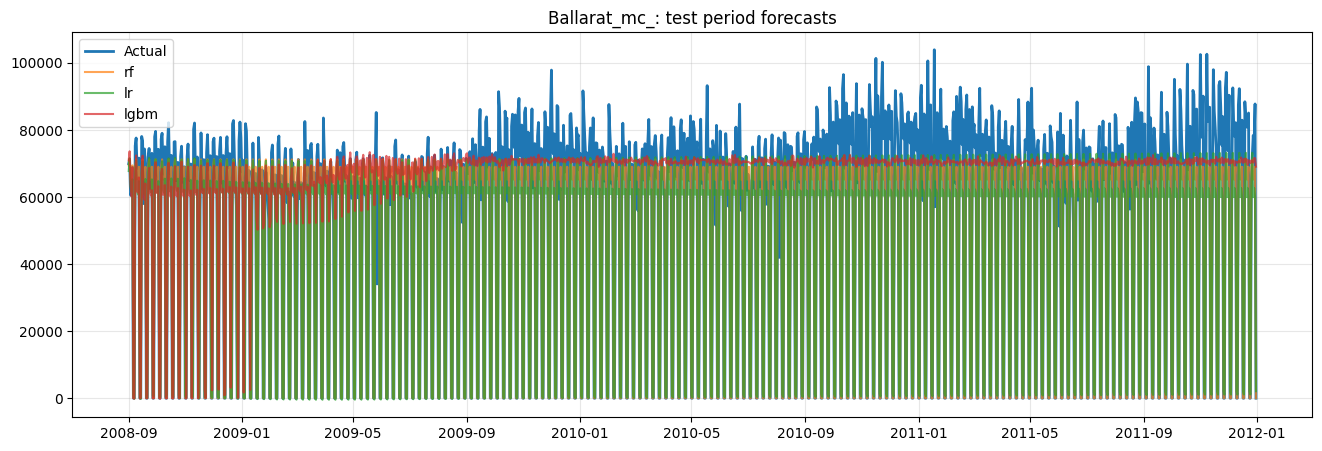

In [22]:
actual = test_series.values().flatten()
n = len(actual)
train_vals = train_series.values().flatten()
weekday_mean = pd.Series(train_vals).groupby(train_series.time_index.dayofweek.to_numpy()).mean()

baselines = {
    "baseline: mean of training": np.full(n, train_vals.mean()),
    "baseline: same weekday last week": np.tile(train_vals[-7:], n // 7 + 1)[:n],
    "baseline: weekday average": weekday_mean.reindex(test_series.time_index.dayofweek).to_numpy(),
}

rows = {label: {k: v for k, v in r.items() if k != "model_name"} for label, r in all_results.items()}
for name, p in baselines.items():
    rows[name] = scores(actual, p)

table = pd.DataFrame(rows).T.sort_values("rmse")
display(table.round(2))
table.to_csv(f"{OUTPUT_DIR}/all_models_test_scores_ballarat.csv")

plt.figure(figsize=(16, 5))
plt.plot(test_series.time_index, actual, label="Actual", linewidth=2)
for label, p in all_preds.items():
    plt.plot(test_series.time_index, p, label=label, alpha=0.7)
plt.legend(); plt.grid(alpha=0.3); plt.title(f"{DATASET_NAME}: test period forecasts")
plt.savefig(f"{OUTPUT_DIR}/all_models_forecast_ballarat.png", dpi=150)
plt.show()

In [23]:
   print(list(all_results.keys()))
   for k, v in all_results.items():
       print(k, "->", v["model_name"])
   print("Zero days in test:", int((actual == 0).sum()))

['rf', 'lr', 'lgbm']
rf -> rf_lags-7_n_estimators-10_max_depth-4
lr -> lr_lags-90
lgbm -> lgbm_lags-60
Zero days in test: 347
